# L10 · Memoria por conversación con un agente

*Advanced Topics in Analytics II - Generative AI* · Instructor: Sergio A. Mora Pardo

En [L9](L09-ConversationalRAG.ipynb) el historial era una lista de Python que pasábamos a mano, y **nosotros** decidíamos cómo reformular la pregunta. Ahora juntamos dos ideas que ya conocemos: el agente de L4, que decide cuándo usar una herramienta, y el índice de las políticas de **ACME**, convertido en esa herramienta. El agente **escribe su propia búsqueda**.

Para que recuerde la conversación, LangGraph guarda el estado con un **checkpointer**, separado por `thread_id`: cada conversación tiene su historial y no ve el de las demás.

## Qué construimos

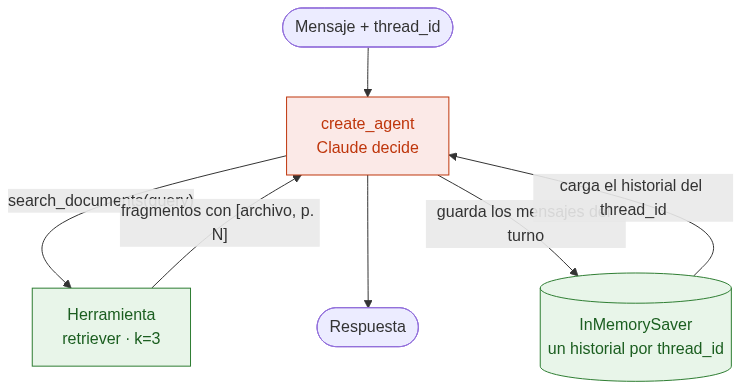

<details><summary>Código Mermaid</summary>

```mermaid
flowchart TB
    U(["Mensaje + thread_id"]) --> AG["create_agent<br/>Claude decide"]
    AG -->|"search_documents(query)"| T["Herramienta<br/>retriever · k=3"]
    T -->|"fragmentos con [archivo, p. N]"| AG
    AG --> A(["Respuesta"])
    AG -->|"guarda los mensajes del turno"| CP[("InMemorySaver<br/>un historial por thread_id")]
    CP -->|"carga el historial del thread_id"| AG

    classDef local fill:#e8f5e9,stroke:#2e7d32,color:#1b5e20
    classDef claude fill:#fbe9e7,stroke:#bf360c,color:#bf360c
    class T,CP local
    class AG claude
```

</details>

## Objetivos

Al terminar podrás:

1. Convertir el retriever en una herramienta con `@tool` y dársela a un agente.
2. Comprobar que un agente sin checkpointer olvida el turno anterior.
3. Añadir memoria con `InMemorySaver` y un `thread_id`.
4. Leer el estado guardado y comprobar que dos conversaciones no se mezclan.
5. Explicar por qué el historial crece en cada turno y qué cambia en producción.

## Metodología

- **La misma conversación de L9**: 45 días de mora, «¿puedo reestructurarlo?» y «¿Y cuántas veces puedo hacerlo?», más un turno sobre las centrales de riesgo.
- **Leer las llamadas a la herramienta**: qué consulta escribió el agente dice más que la respuesta final.
- **Un concepto por sección.** Las llamadas a Claude están en las secciones 2, 3 y 5.

## Contenido

- [0. Preparación](#0.-Preparación)
- [1. El retriever como herramienta](#1.-El-retriever-como-herramienta)
- [2. Un agente sin memoria](#2.-Un-agente-sin-memoria)
- [3. Memoria con un checkpointer](#3.-Memoria-con-un-checkpointer)
- [4. Qué guarda el checkpointer](#4.-Qué-guarda-el-checkpointer)
- [5. Conversaciones aisladas](#5.-Conversaciones-aisladas)
- [6. El historial crece](#6.-El-historial-crece)
- [Práctica breve](#Práctica-breve)
- [Referencias](#Referencias)

El recorrido realiza **entre 8 y 16 llamadas a Claude Haiku**: el agente decide cuántas veces buscar. Lo habitual son 10.

## 0. Preparación

Los mismos modelos de L9. LangSmith es opcional: con `LANGSMITH_TRACING=true`, un recorrido completo genera **7 trazas**: la herramienta probada sola en la sección 1 y cada `agent.invoke` de las secciones 2, 3 y 5, con las llamadas del modelo y de la herramienta adentro.

In [1]:
import os

from dotenv import find_dotenv, load_dotenv
from langchain_anthropic import ChatAnthropic
from langchain_community.embeddings import FastEmbedEmbeddings

# find_dotenv sube por las carpetas hasta encontrar el .env de la raíz
load_dotenv(find_dotenv())

model = ChatAnthropic(
    model="claude-haiku-5-5",
    max_tokens=500,
    thinking={"type": "disabled"},
    timeout=60,
    max_retries=2,
)
# Modelo abierto y multilingüe: corre en este equipo, sin API key ni costo por uso.
embeddings = FastEmbedEmbeddings(model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
print("Trazas en LangSmith:", os.getenv("LANGSMITH_TRACING", "false"))

Trazas en LangSmith: false


## 1. El retriever como herramienta

Sin modelo. Cargamos el índice de L8 en una celda, igual que en L9.

In [2]:
from pathlib import Path

from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pypdf import PdfReader

pages = []
for path in sorted(Path("../datasets").glob("acme_*.pdf")):
    for number, page in enumerate(PdfReader(path).pages, 1):
        pages.append(Document(page.extract_text(), metadata={"source": path.name, "page": number}))

chunks = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=60).split_documents(pages)
vector_store = InMemoryVectorStore.from_documents(chunks, embeddings)
retriever = vector_store.as_retriever(search_kwargs={"k": 3})


def format_docs(docs):
    return "\n\n".join(f"[{doc.metadata['source']}, p. {doc.metadata['page']}]\n{doc.page_content}" for doc in docs)


print(len(pages), "páginas →", len(chunks), "fragmentos")

8 páginas → 26 fragmentos


Como en L4, `@tool` convierte una función en una herramienta: el nombre, la *docstring* y los tipos son lo que lee el modelo para decidir cuándo usarla y con qué argumentos. La docstring pide una **consulta completa**: es la reformulación de L9, ahora como instrucción para el agente.

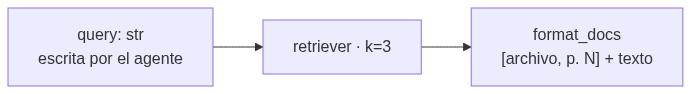

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    Q["query: str<br/>escrita por el agente"] --> R["retriever · k=3"] --> F["format_docs<br/>[archivo, p. N] + texto"]
```

</details>

In [3]:
from langchain_core.tools import tool


@tool(parse_docstring=True)
def search_documents(query: str) -> str:
    """Busca en las políticas de ACME: crédito, desembolsos, costos y pagos, y cobranza.

    Args:
        query: pregunta completa, con el producto, la situación del cliente y el tema; sin pronombres como «eso».
    """
    return format_docs(retriever.invoke(query))


print(search_documents.invoke({"query": "¿Se puede reestructurar un crédito con 45 días de mora?"})[:300])

[acme_collections_policy.pdf, p. 2]
3. Reestructuración
- Un cliente con hasta 90 días de mora puede solicitar una reestructuración de su crédito desde la app.
- La reestructuración puede ampliar el plazo restante hasta en 24 meses, sin superar el plazo máximo
del producto.
- Cada crédito admite una


## 2. Un agente sin memoria

`create_agent` de L4, con la nueva herramienta y un *system prompt* para el soporte de ACME. Le pasamos el mensaje como `HumanMessage`, la misma clase que guarda el agente en su estado. Le hacemos la primera pregunta de la conversación (**unas 2 llamadas**: decidir la búsqueda y responder).

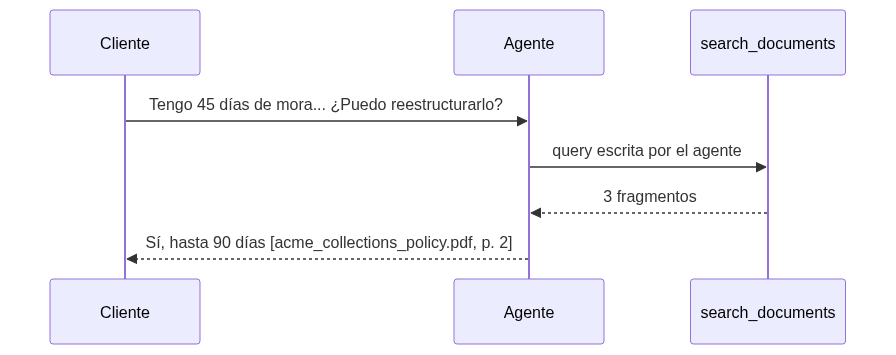

<details><summary>Código Mermaid</summary>

```mermaid
sequenceDiagram
    participant U as Cliente
    participant A as Agente
    participant T as search_documents
    U->>A: Tengo 45 días de mora... ¿Puedo reestructurarlo?
    A->>T: query escrita por el agente
    T-->>A: 3 fragmentos
    A-->>U: Sí, hasta 90 días [acme_collections_policy.pdf, p. 2]
```

</details>

In [4]:
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

SYSTEM_PROMPT = """\
Eres el asistente de soporte de ACME, una fintech. Responde siempre en español.
Para responder sobre créditos, desembolsos, pagos o cobranza, busca siempre en las políticas con la herramienta.
Escribe la búsqueda como una pregunta completa, con el producto, la situación del cliente y el tema, aunque el usuario se refiera a mensajes anteriores.
Responde solo con los fragmentos que devuelve la herramienta y cita cada dato con el formato [archivo, p. N].
Si los fragmentos no contienen la respuesta, di que no está en los documentos consultados y no la inventes.
No prometas aprobaciones ni des asesoría financiera personalizada.
"""

agent = create_agent(model, tools=[search_documents], system_prompt=SYSTEM_PROMPT)

first_question = "Tengo 45 días de mora en mi Crédito Libre Inversión. ¿Puedo reestructurarlo?"
follow_up = "¿Y cuántas veces puedo hacerlo?"

In [5]:
first_result = agent.invoke({"messages": [HumanMessage(first_question)]})

for message in first_result["messages"]:
    message.pretty_print()

================================ Human Message =================================

Tengo 45 días de mora en mi Crédito Libre Inversión. ¿Puedo reestructurarlo?
================================== Ai Message ==================================

[{'text': 'Voy a buscar en las políticas de ACME sobre reestructuración para este caso.', 'type': 'text'}, {'id': 'toolu_012ujgXAwPPiyGJPKzt5N1jg', 'caller': {'type': 'direct'}, 'input': {'query': '¿Puede un cliente con 45 días de mora en su Crédito Libre Inversión reestructurar el crédito según las políticas de cobranza de ACME?'}, 'name': 'search_documents', 'type': 'tool_use', 'toolset_name': None}]
Tool Calls:
  search_documents (toolu_012ujgXAwPPiyGJPKzt5N1jg)
 Call ID: toolu_012ujgXAwPPiyGJPKzt5N1jg
  Args:
    query: ¿Puede un cliente con 45 días de mora en su Crédito Libre Inversión reestructurar el crédito según las políticas de cobranza de ACME?
================================= Tool Message =================================
Name: search_d

Ahora la pregunta de seguimiento, con otro `invoke`. Cada `invoke` empieza con la lista de mensajes que le pasamos, y aquí solo le pasamos la pregunta nueva.

In [6]:
forgetful_result = agent.invoke({"messages": [HumanMessage(follow_up)]})

print("Búsquedas:", [call["args"]["query"] for message in forgetful_result["messages"] if message.type == "ai" for call in message.tool_calls])
print(forgetful_result["messages"][-1].text)

Búsquedas: []
No tengo el contexto de a qué se refiere "hacerlo", así que voy a necesitar más detalles. Para poder buscar en las políticas de ACME, ¿podrías indicarme qué quieres hacer (por ejemplo, un desembolso, un pago anticipado, una reestructuración o una solicitud de crédito) y qué producto tienes o estás considerando?


El agente no sabe qué es «hacerlo». Revisa la búsqueda que escribió: no menciona la reestructuración ni la mora, porque no conoce el turno anterior. Puede responder con datos ciertos de otro tema o pedir que le aclaren. **El agente no guarda nada entre un `invoke` y el siguiente.** En L9 resolvíamos esto pasando `history` a mano.

## 3. Memoria con un checkpointer

Un **checkpointer** guarda el estado del agente (la lista de mensajes) después de cada paso. `InMemorySaver` lo guarda en la memoria del notebook. Cada `invoke` lleva un `thread_id` en `config`: el agente carga los mensajes de ese hilo, añade el nuevo y guarda el resultado.

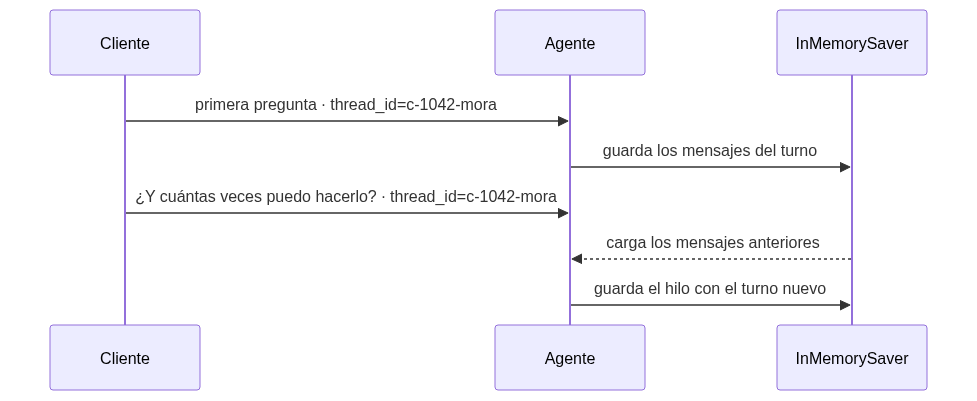

<details><summary>Código Mermaid</summary>

```mermaid
sequenceDiagram
    participant U as Cliente
    participant A as Agente
    participant C as InMemorySaver
    U->>A: primera pregunta · thread_id=c-1042-mora
    A->>C: guarda los mensajes del turno
    U->>A: ¿Y cuántas veces puedo hacerlo? · thread_id=c-1042-mora
    C-->>A: carga los mensajes anteriores
    A->>C: guarda el hilo con el turno nuevo
```

</details>

En una aplicación, el `thread_id` identifica la conversación de un cliente: dos clientes con el mismo `thread_id` verían una sola conversación mezclada. Hacemos la misma conversación (**unas 3 llamadas**).

In [7]:
from langgraph.checkpoint.memory import InMemorySaver

memory_agent = create_agent(
    model,
    tools=[search_documents],
    system_prompt=SYSTEM_PROMPT,
    checkpointer=InMemorySaver(),
)
config = {"configurable": {"thread_id": "c-1042-mora"}}

memory_agent.invoke({"messages": [HumanMessage(first_question)]}, config)
memory_result = memory_agent.invoke({"messages": [HumanMessage(follow_up)]}, config)

print(memory_result["messages"][-1].text)

Según la política de cobranza, cada crédito admite **una sola reestructuración por año** [acme_collections_policy.pdf, p. 2]. Los documentos consultados no indican un límite total de reestructuraciones a lo largo de la vida del crédito.


¿Volvió a buscar? Puede que no: los fragmentos de la reestructuración ya estaban en el hilo, en el mensaje de la herramienta del primer turno, y el agente decide que le bastan. Un tercer turno cambia de tema y necesita otro fragmento (**unas 2 llamadas**):

In [8]:
reporting_question = "¿Y mientras tanto ya me reportan a las centrales de riesgo?"
reporting_result = memory_agent.invoke({"messages": [HumanMessage(reporting_question)]}, config)

print(reporting_result["messages"][-1].text)

Los documentos consultados no dicen cuándo exactamente se reporta un cliente en mora a las centrales de riesgo, ni cómo queda el reporte mientras se tramita una reestructuración.

Lo único que encontré es que, cuando el cliente se pone al día, ACME actualiza el reporte en las centrales de riesgo en un máximo de 10 días hábiles [acme_collections_policy.pdf, p. 2]. Además, según la política, una reestructuración aprobada no borra el historial de mora ya reportado [acme_collections_policy.pdf, p. 2].

Para confirmar si ya tienes un reporte activo, te recomiendo consultar directamente con ACME.


¿Qué consultas escribió el agente para la herramienta? Las buscamos en las llamadas a herramientas de todo el hilo, como en L4:

In [9]:
searches = [call["args"]["query"] for message in reporting_result["messages"] if message.type == "ai" for call in message.tool_calls]
searches

['¿Puede un cliente con Crédito Libre Inversión con 45 días de mora reestructurar su crédito según las políticas de ACME de cobranza y reestructuración?',
 '¿Cuándo reporta ACME a un cliente con Crédito Libre Inversión en mora a las centrales de riesgo y qué pasa con el historial durante una reestructuración?']

Si el agente no volvió a buscar en el segundo turno, verás solo dos consultas: la del primero y la del tercero. La del tercer turno debería ser una pregunta completa sobre las centrales de riesgo con 45 días de mora, aunque el cliente escribió «mientras tanto». Es la reformulación de L9, pero ahora **la decide el agente**: decide **si** busca y **qué** escribe.

Lee también la respuesta: ¿dice con cuántos días de anticipación avisa ACME antes de reportar? La política dice 20 días calendario, pero esa cifra quedó al inicio del fragmento siguiente, y la búsqueda puede no traerlo. Un corte de fragmento a mitad de frase también se nota en las respuestas.

| | L9 · `conversational_rag` | L10 · agente con checkpointer |
|---|---|---|
| Historial | Lista que pasamos a mano | Lo guarda el checkpointer por `thread_id` |
| Reformulación | Siempre, con `REWRITE_PROMPT` | El agente decide si busca y escribe la consulta |
| Llamadas por pregunta | Siempre 2 | Variable: el agente decide si busca y cuántas veces |
| Control | Más predecible | Más flexible |

## 4. Qué guarda el checkpointer

Sin modelo. `get_state` devuelve el último estado guardado de un hilo. Sus `values` tienen la lista de mensajes de toda la conversación: preguntas del cliente, llamadas a la herramienta, fragmentos devueltos y respuestas.

In [10]:
state = memory_agent.get_state(config)
messages = state.values["messages"]

print(len(messages), "mensajes en el hilo", config["configurable"]["thread_id"])
[message.type for message in messages]

10 mensajes en el hilo c-1042-mora


['human', 'ai', 'tool', 'ai', 'human', 'ai', 'human', 'ai', 'tool', 'ai']

Los mensajes `tool` también se guardan: en el siguiente turno el modelo vuelve a leer los fragmentos que ya recuperó. Por eso el agente puede responder una pregunta de seguimiento sin volver a buscar… y por eso también podría responder con fragmentos viejos cuando debía buscar de nuevo.

## 5. Conversaciones aisladas

Otro cliente empieza directamente con la pregunta de seguimiento (**1 o 2 llamadas**). Usa el mismo agente, con otro `thread_id`.

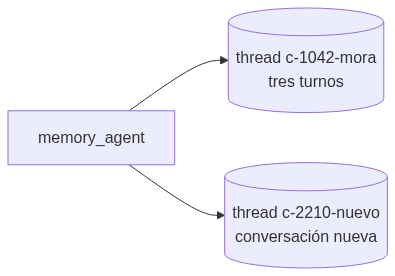

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    A["memory_agent"] --> T1[("thread c-1042-mora<br/>tres turnos")]
    A --> T2[("thread c-2210-nuevo<br/>conversación nueva")]
```

</details>

In [11]:
other_config = {"configurable": {"thread_id": "c-2210-nuevo"}}
other_result = memory_agent.invoke({"messages": [HumanMessage(follow_up)]}, other_config)

print(other_result["messages"][-1].text)

Para poder responderte necesito saber a qué te refieres con "hacerlo". No veo mensajes anteriores en esta conversación, así que no sé si hablas de un pago anticipado, una reestructuración, un desembolso u otra operación.

¿Podrías indicarme el producto (por ejemplo, crédito personal o de nómina) y la operación que quieres realizar? Con eso podré buscar la política correspondiente y responderte con base en los documentos de ACME.


In [12]:
for thread in (config, other_config):
    values = memory_agent.get_state(thread).values
    print(thread["configurable"]["thread_id"], "→", len(values["messages"]), "mensajes")

c-1042-mora → 10 mensajes
c-2210-nuevo → 2 mensajes


Sin contexto, el agente debería pedir que le aclaren qué es «eso». Revisa si en la aclaración menciona productos que ACME no ofrece: las políticas solo hablan del Crédito Express y del Crédito Libre Inversión.

El hilo `c-2210-nuevo` no conoce la mora del otro cliente: el checkpointer **aísla** las conversaciones. En una aplicación, el `thread_id` sale de la sesión del usuario.

**Las conversaciones en LangSmith.** LangGraph copia el `thread_id` a la metadata de cada traza, y LangSmith agrupa por ese valor en la pestaña **Threads** del proyecto. Con `LANGSMITH_TRACING=true`, abre tu proyecto en [LangSmith](https://smith.langchain.com), entra a **Threads** y busca `c-1042-mora`: los tres turnos aparecen como una sola conversación, con la traza completa de cada uno.

## 6. El historial crece

Sin modelo. Cada respuesta del modelo trae en `usage_metadata` cuántos tokens de entrada leyó. En el hilo `c-1042-mora`, cada llamada lee todo lo anterior: preguntas, fragmentos y respuestas.

In [13]:
for message in messages:
    if message.type == "ai":
        print("Tokens de entrada:", message.usage_metadata["input_tokens"])

Tokens de entrada: 712
Tokens de entrada: 1302
Tokens de entrada: 1764
Tokens de entrada: 1883
Tokens de entrada: 2430


Una conversación larga cuesta más en cada turno y puede llenar la ventana de contexto. Las aplicaciones recortan o resumen el historial; LangChain ofrece `trim_messages`, y con LangGraph (semana 8) decidiremos qué se guarda en el estado.

**En producción la memoria no vive en el notebook.** `InMemorySaver` se pierde al reiniciar el kernel. En la semana 12, la API del curso usa el checkpointer de PostgreSQL con el mismo `thread_id`, y la conversación sobrevive a reinicios del servidor. El código del agente no cambia: solo el checkpointer que recibe.

Y la memoria **no reemplaza una consulta actual**: si el saldo o el estado del crédito cambió desde el turno anterior, hay que volver a consultar la fuente.

## Práctica breve

1. En el hilo `c-1042-mora`, pregunta *«¿Y si pierdo el empleo, qué puedo hacer?»*. Revisa con la sección 3 si el agente volvió a buscar o respondió con los fragmentos que ya tenía.
2. Crea un tercer hilo y hazle primero la pregunta completa y luego *«¿Y eso aplica también para mi tarjeta de crédito?»*. ¿Dice que no está en los documentos?
3. Quita del *system prompt* la línea «Escribe la búsqueda como una pregunta completa…», crea el agente de nuevo y repite la sección 3. ¿Cambia la consulta que escribe?
4. Compara L9 y L10 con tres preguntas de seguimiento propias: ¿cuál responde mejor y cuántas llamadas hace cada uno?

## Referencias

**Learning LangChain**, Mayo Oshin y Nuno Campos, O'Reilly: [`ch4/py/c-persistent-memory.py`](https://github.com/langchain-ai/learning-langchain/blob/master/ch4/py/c-persistent-memory.py) (checkpointer, `thread_id` y `get_state`, secciones 3 y 4) y [`ch5/py/a-chatbot.py`](https://github.com/langchain-ai/learning-langchain/blob/master/ch5/py/a-chatbot.py) (el estado con la lista de mensajes que se acumula). El libro arma el grafo con `StateGraph` y `MemorySaver`; aquí usamos `create_agent` e `InMemorySaver`, el nombre actual.

**Building Applications with AI Agents**, Michael Albada, [`short_term_memory.py`](https://github.com/michaelalbada/BuildingApplicationsWithAIAgents/blob/main/src/frameworks/langgraph_agents/short_term_memory.py): ejecuciones con y sin checkpointer.

- [Memoria de corto plazo en LangChain](https://docs.langchain.com/oss/python/langchain/short-term-memory)
- [Persistencia en LangGraph](https://docs.langchain.com/oss/python/langgraph/persistence)